# Week 7 - Classification & Neural Networks

## Machine Learning for Engineering Applications

## By the end of this seminar you should be able to:
1. Apply core classification algorithms:
   - Logistic Regression
   - k-Nearest Neighbours (kNN)
   - Decision Trees
   - Random Forests
   - Support Vector Machines (SVM)

2. Evaluate classification models using:
   - Accuracy
   - Precision
   - Recall
   - F1-score
   - Confusion Matrix
   - ROC-AUC

3. Understand the challenges posed by imbalanced datasets in engineering applications.

4. Build and train a simple Artificial Neural Network (ANN) using Keras.

Please note the dataset is **synthetic** and is designed for teaching rather than representing a real machine.

More examples of classification with scikit-learn can be found at: https://scikit-learn.org/stable/auto_examples/classification/index.html


## Dataset Overview: Predictive Maintenance of Rotating Machinery
Predictive maintenance aims to identify developing faults in machines before catastrophic failure occurs. Modern condition-monitoring systems collect sensor measurements such as vibration amplitude, temperature and rotational speed, which can be analysed using machine learning algorithms to classify machine health states.

In this lab, you will work with a vibration monitoring dataset collected from a simulated industrial rotating machine. The dataset is similar to the dataset which we looked at in the Week 2 seminar on dataset and pre-processing. However, the new dataset has more data entries, and some cleaning has already been applied: (1) removed entries with missing values; (2) removed duplicate records; (3) removed obvious outliers intended for preprocessing exercises. The objective is to use machine learning classification techniques to identify the health condition of the machine based on measurements obtained from vibration sensors and operating parameters.

The dataset contains observations from four different operating conditions:

* Healthy: Normal machine operation with low vibration levels.
* Run-Up (Transient): Machine accelerating from low to rated speed. These data points represent normal but non-steady-state behaviour.
* Bearing Fault: Simulated inner-race bearing damage, resulting in increased vibration levels and impulsive behaviour.
* Rotor Imbalance: Uneven mass distribution on the rotating shaft, causing elevated vibration at the rotational frequency.

For each observation, several sensor-derived features are available:

* RPM: Rotational speed of the machine.
* Temperature: Operating temperature.
* RMS Vibration: Overall vibration energy.
* Peak Vibration: Maximum vibration amplitude.
* Kurtosis: Indicator of impulsive events often associated with bearing faults.
* Skewness: Measure of the asymmetry of the vibration signal distribution.

Before building a machine learning classification model, you should investigate and address potential data issues through an appropriate preprocessing pipeline which we discussed during the Week 2 lecture on datasets and pre-processing. Typical preprocessing steps include duplicate removal, missing value treatment, outlier analysis, feature scaling, and exploratory data analysis.

The primary task is to use the sensor measurements to **classify** the machine condition (FaultLabel), allowing the development of a simple predictive maintenance model capable of distinguishing between healthy operation and different fault types. This exercise demonstrates the complete workflow from raw engineering data to machine learning-based condition monitoring.


## Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

from sklearn.preprocessing import label_binarize

## Load the Dataset

In [5]:
df = pd.read_csv("dataset.csv")

df.head()

,RecordID,RPM,Temperature_C,RMS_g,Peak_g,Kurtosis,Skewness,OperatingState,FaultLabel
0,1,1808.941,45.751,0.239,0.838,4.066,-0.082,Healthy,Healthy
1,2,1795.786,48.843,0.243,0.851,2.671,0.190,Healthy,Healthy
2,3,1791.658,45.162,0.227,0.795,1.661,-0.604,Healthy,Healthy
3,4,1789.879,44.177,0.229,0.803,2.364,-0.494,Healthy,Healthy
4,5,1826.382,45.594,0.222,0.777,2.003,-0.191,Healthy,Healthy


### Check the dataset dimensions:

In [6]:
print(df.shape)

(1800, 9)


### Display summary information:

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RecordID        1800 non-null   int64  
 1   RPM             1800 non-null   float64
 2   Temperature_C   1800 non-null   float64
 3   RMS_g           1800 non-null   float64
 4   Peak_g          1800 non-null   float64
 5   Kurtosis        1800 non-null   float64
 6   Skewness        1800 non-null   float64
 7   OperatingState  1800 non-null   str    
 8   FaultLabel      1800 non-null   str    
dtypes: float64(6), int64(1), str(2)
memory usage: 126.7 KB


## Exploratory Data Analysis

### Class Distribution

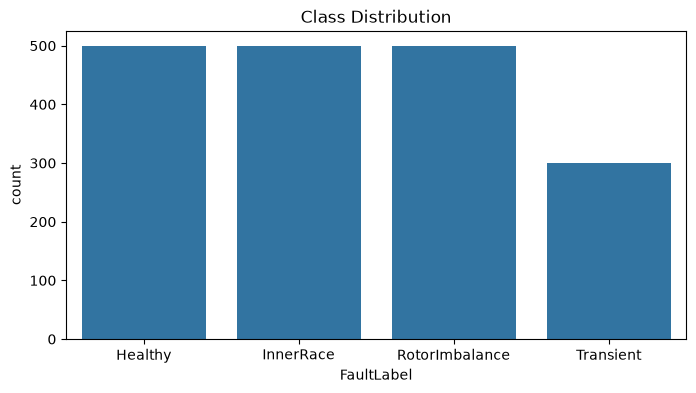

In [9]:
df['FaultLabel'].value_counts()
plt.figure(figsize=(8,4))

sns.countplot(data=df,
              x='FaultLabel',
              order=df['FaultLabel'].value_counts().index)

plt.title("Class Distribution")
plt.show()

### Feature Statistics

In [10]:
df.describe()

,RecordID,RPM,Temperature_C,RMS_g,Peak_g,Kurtosis,Skewness
count,1800.00000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000
mean,900.50000,1699.024209,51.023662,0.587088,2.423038,5.690298,0.046417
std,519.75956,263.345306,4.959238,0.293414,1.350463,1.885318,0.432840
min,1.00000,606.300000,40.208000,0.068000,0.271000,1.144000,-1.844000
25%,450.75000,1768.292000,46.884000,0.255000,0.899250,3.817500,-0.225250
50%,900.50000,1793.426000,50.609500,0.602000,2.409000,6.226500,0.035500
75%,1350.25000,1810.072000,54.612250,0.819250,3.501500,7.101000,0.334000
max,1800.00000,1874.747000,66.729000,1.328000,5.844000,9.504000,1.421000


### Correlation Matrix

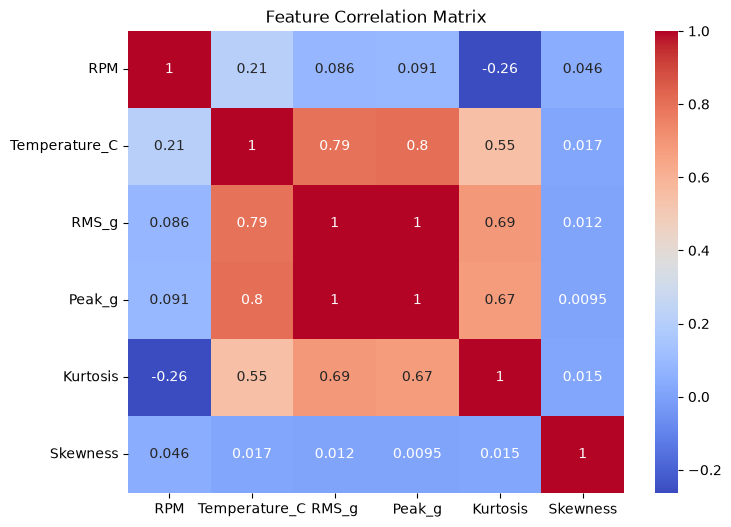

In [12]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[['RPM',
        'Temperature_C',
        'RMS_g',
        'Peak_g',
        'Kurtosis',
        'Skewness']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Feature Correlation Matrix")
plt.show()

### Pairplot

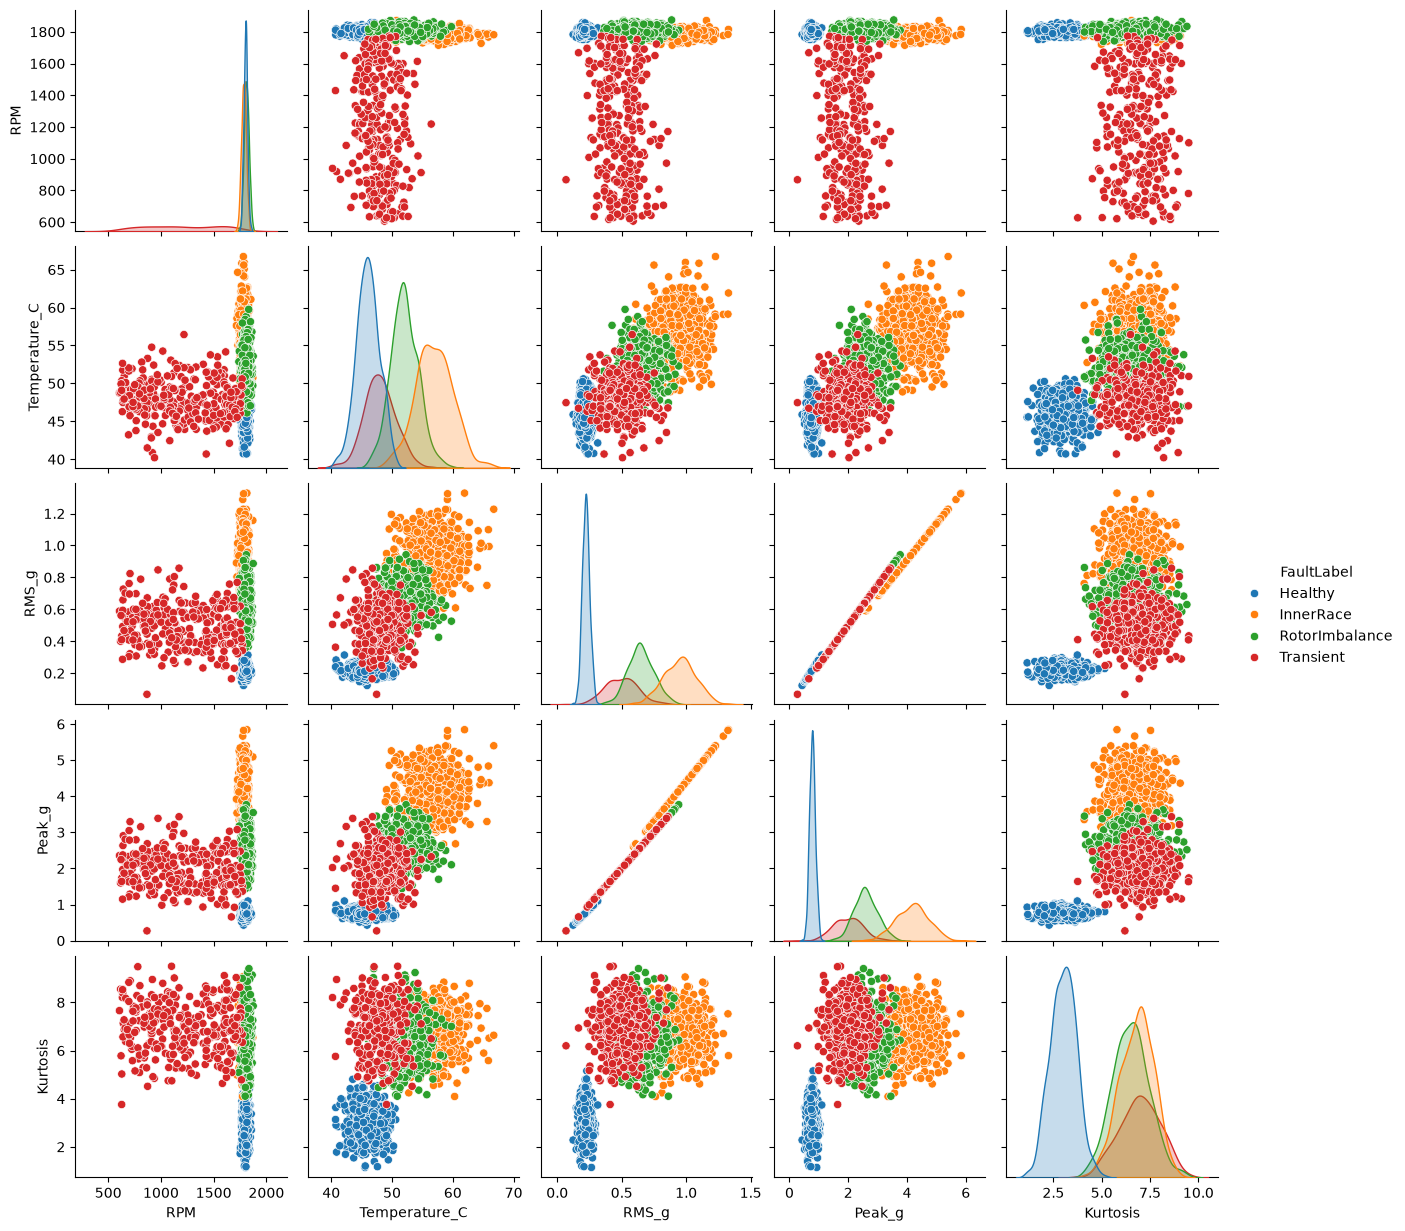

In [13]:
sns.pairplot(
    df,
    vars=['RPM',
          'Temperature_C',
          'RMS_g',
          'Peak_g',
          'Kurtosis'],
    hue='FaultLabel'
)

plt.show()

### Discussion (with your neighbours):

- Which features appear most useful?
- Which classes overlap?
- Which classes appear easy to separate?

## Prepare Features and Labels

In [14]:
X = df[['RPM',
        'Temperature_C',
        'RMS_g',
        'Peak_g',
        'Kurtosis',
        'Skewness']]

y = df['FaultLabel']

## Train-Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Check class balance:

In [16]:
y_train.value_counts(normalize=True)

FaultLabel
InnerRace         0.277778
Healthy           0.277778
RotorImbalance    0.277778
Transient         0.166667
Name: proportion, dtype: float64

## A Reusable Evaluation Function

In [17]:
def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    print(f"Accuracy = {acc:.3f}")

    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )

    disp.plot(cmap='Blues')
    plt.show()

## Logistic Regression

Accuracy = 0.986
                precision    recall  f1-score   support

       Healthy       1.00      1.00      1.00       100
     InnerRace       0.98      0.97      0.97       100
RotorImbalance       0.97      0.98      0.98       100
     Transient       1.00      1.00      1.00        60

      accuracy                           0.99       360
     macro avg       0.99      0.99      0.99       360
  weighted avg       0.99      0.99      0.99       360



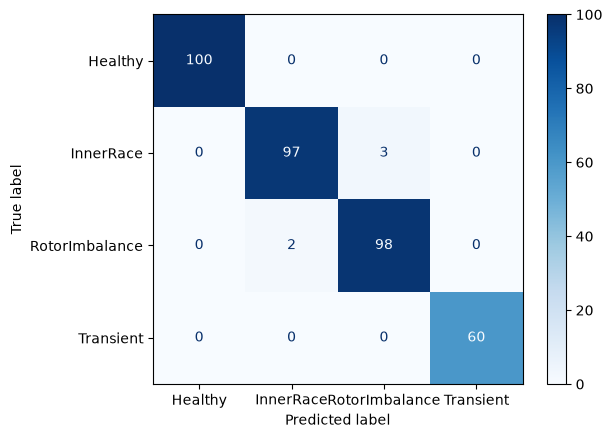

In [18]:
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000))
])

lr_model.fit(X_train, y_train)

evaluate_model(lr_model, X_test, y_test)

## k-Nearest Neighbours

Accuracy = 0.961
                precision    recall  f1-score   support

       Healthy       1.00      1.00      1.00       100
     InnerRace       0.95      0.94      0.94       100
RotorImbalance       0.91      0.95      0.93       100
     Transient       1.00      0.95      0.97        60

      accuracy                           0.96       360
     macro avg       0.97      0.96      0.96       360
  weighted avg       0.96      0.96      0.96       360



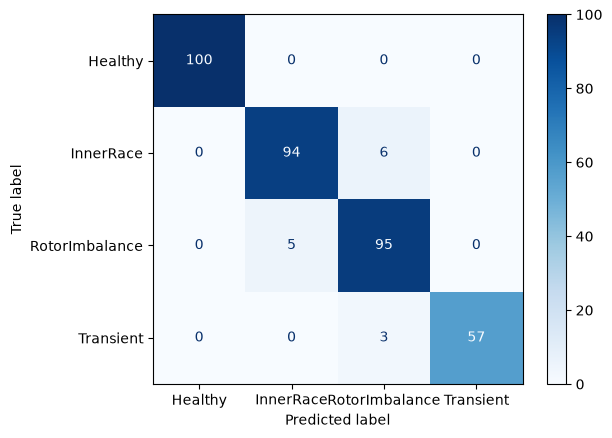

In [19]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

evaluate_model(knn_model, X_test, y_test)

## Decision Tree

Accuracy = 0.983
                precision    recall  f1-score   support

       Healthy       1.00      1.00      1.00       100
     InnerRace       0.97      0.98      0.98       100
RotorImbalance       0.97      0.97      0.97       100
     Transient       1.00      0.98      0.99        60

      accuracy                           0.98       360
     macro avg       0.99      0.98      0.98       360
  weighted avg       0.98      0.98      0.98       360



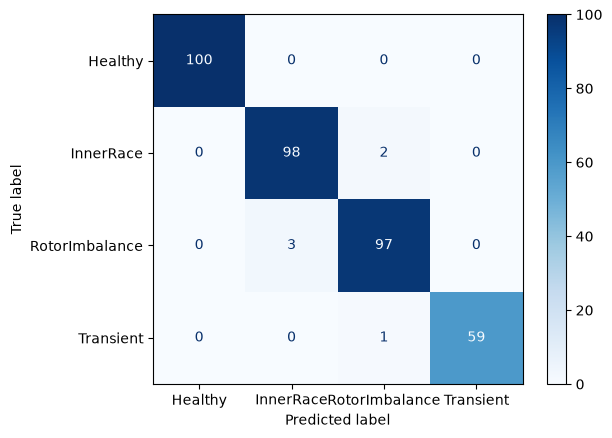

In [20]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

evaluate_model(dt_model, X_test, y_test)

### Visualise the tree:

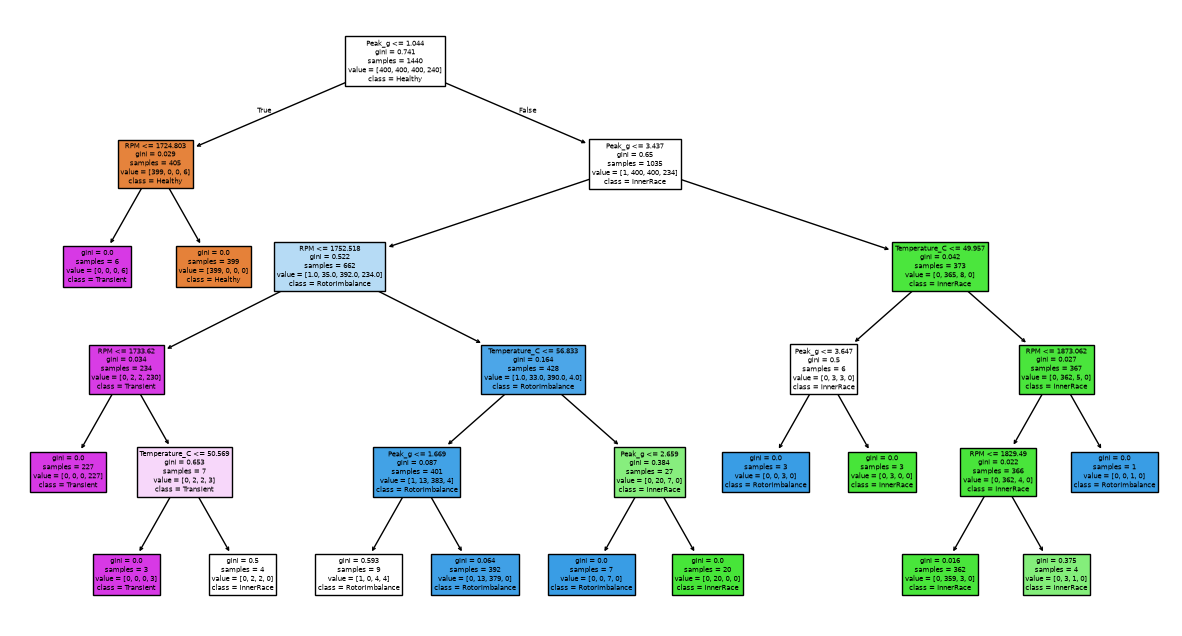

In [21]:
from sklearn.tree import plot_tree

plt.figure(figsize=(15,8))

plot_tree(
    dt_model,
    filled=True,
    feature_names=X.columns,
    class_names=dt_model.classes_
)

plt.show()

## Random Forest

Accuracy = 0.983
                precision    recall  f1-score   support

       Healthy       1.00      1.00      1.00       100
     InnerRace       0.98      0.97      0.97       100
RotorImbalance       0.96      0.98      0.97       100
     Transient       1.00      0.98      0.99        60

      accuracy                           0.98       360
     macro avg       0.99      0.98      0.98       360
  weighted avg       0.98      0.98      0.98       360



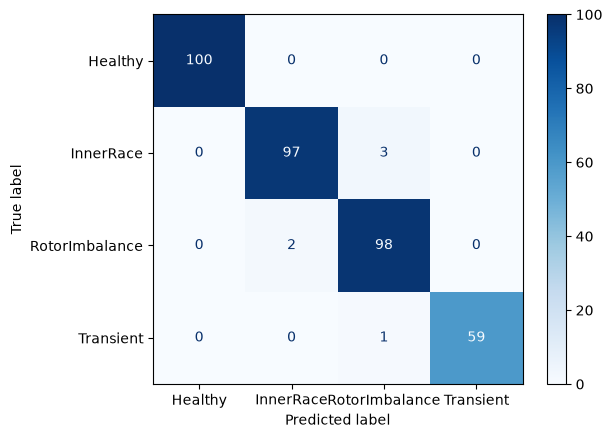

In [22]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

evaluate_model(rf_model, X_test, y_test)

### Feature importance:

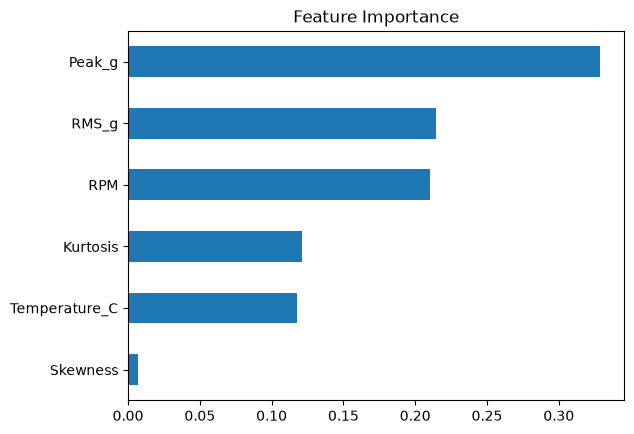

In [23]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
)

importance.sort_values().plot(kind='barh')

plt.title("Feature Importance")
plt.show()

## Support Vector Machine

Accuracy = 0.972
                precision    recall  f1-score   support

       Healthy       1.00      1.00      1.00       100
     InnerRace       0.96      0.96      0.96       100
RotorImbalance       0.94      0.96      0.95       100
     Transient       1.00      0.97      0.98        60

      accuracy                           0.97       360
     macro avg       0.98      0.97      0.97       360
  weighted avg       0.97      0.97      0.97       360



C:\Users\ezzsl2\AppData\Local\miniconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


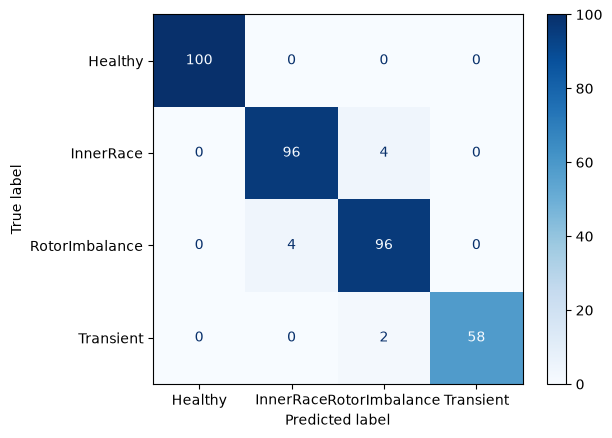

In [24]:
from sklearn.svm import SVC

svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier',
     SVC(
         kernel='rbf',
         probability=True
     ))
])

svm_model.fit(X_train, y_train)

evaluate_model(svm_model, X_test, y_test)

## Model Comparison

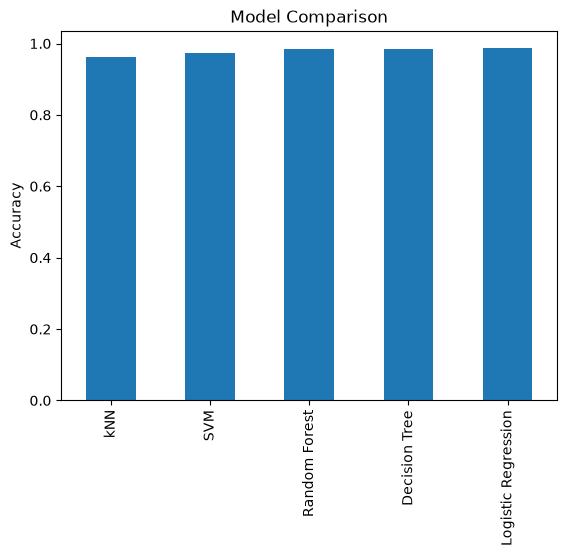

In [25]:
results = {}

models = {
    "Logistic Regression": lr_model,
    "kNN": knn_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "SVM": svm_model
}

for name, model in models.items():

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    results[name] = acc

pd.Series(results).sort_values().plot(kind='bar')

plt.ylabel("Accuracy")
plt.title("Model Comparison")
plt.show()

## ROC-AUC for Multiclass Classification

### Convert labels to binary format:

In [26]:
classes = np.unique(y)

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

### Example using Random Forest:

In [27]:
y_prob = rf_model.predict_proba(X_test)

auc = roc_auc_score(
    y_test_bin,
    y_prob,
    multi_class='ovr'
)

print("ROC-AUC =", auc)

ROC-AUC = 0.9997307692307693


## Engineering Challenge: Imbalanced Data
Real engineering datasets are rarely balanced.

Let's artificially create an imbalanced dataset:

In [28]:
healthy = df[df['FaultLabel'] == 'Healthy']
imbalance = df[df['FaultLabel'] == 'RotorImbalance']
bearing = df[df['FaultLabel'] == 'InnerRace']
transient = df[df['FaultLabel'] == 'Transient']

df_imbalanced = pd.concat([
    healthy.sample(500, random_state=42),
    bearing.sample(80, random_state=42),
    imbalance.sample(80, random_state=42),
    transient.sample(80, random_state=42)
])

df_imbalanced['FaultLabel'].value_counts()

FaultLabel
Healthy           500
InnerRace          80
RotorImbalance     80
Transient          80
Name: count, dtype: int64

### Visualise:

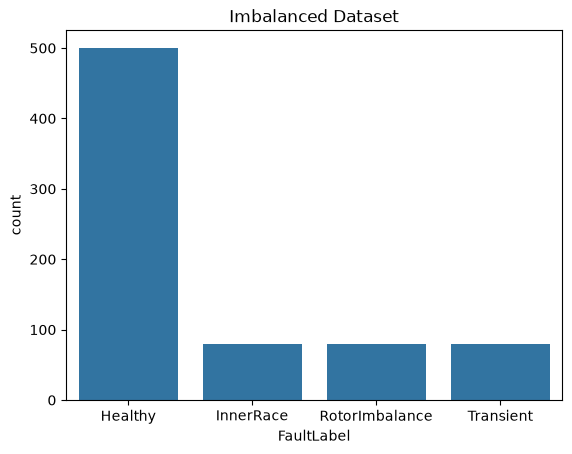

In [29]:
sns.countplot(
    data=df_imbalanced,
    x='FaultLabel'
)

plt.title("Imbalanced Dataset")
plt.show()

### Discussion:

- Why is accuracy alone misleading?
- Which metrics become more important?

## Handling Imbalance Using Class Weights

Accuracy = 0.986
                precision    recall  f1-score   support

       Healthy       1.00      1.00      1.00       100
     InnerRace       0.98      0.97      0.97       100
RotorImbalance       0.97      0.98      0.98       100
     Transient       1.00      1.00      1.00        60

      accuracy                           0.99       360
     macro avg       0.99      0.99      0.99       360
  weighted avg       0.99      0.99      0.99       360



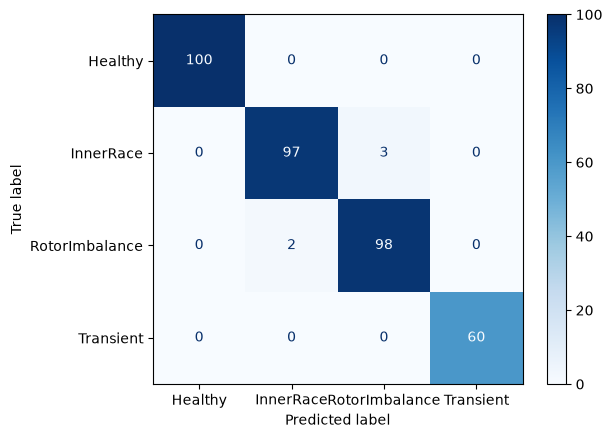

In [30]:
weighted_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42
)

weighted_rf.fit(X_train, y_train)

evaluate_model(weighted_rf, X_test, y_test)

## Build a Neural Network with Keras

### Import TensorFlow/Keras:

In [31]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

### Scale features:

In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Encode target labels:

In [33]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train_enc = encoder.fit_transform(y_train)
y_test_enc = encoder.transform(y_test)

### Convert to one-hot encoding:

In [34]:
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train_enc)
y_test_cat = to_categorical(y_test_enc)

## Define the Neural Network

In [35]:
model = Sequential([
    Dense(32, activation='relu', input_shape=(6,)),
    Dense(16, activation='relu'),
    Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\Users\ezzsl2\AppData\Local\miniconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 4)                   │              68 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 820 (3.20 KB)

 Trainable params: 820 (3.20 KB)

 Non-trainable params: 0 (0.00 B)

## Train the Neural Network

In [36]:
history = model.fit(
    X_train_scaled,
    y_train_cat,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5773 - loss: 1.2374 - val_accuracy: 0.7396 - val_loss: 1.0840
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8090 - loss: 0.9233 - val_accuracy: 0.8403 - val_loss: 0.7921
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8811 - loss: 0.6511 - val_accuracy: 0.8889 - val_loss: 0.5515
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9271 - loss: 0.4440 - val_accuracy: 0.9236 - val_loss: 0.3787
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9505 - loss: 0.3052 - val_accuracy: 0.9444 - val_loss: 0.2672
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9635 - loss: 0.2178 - val_accuracy: 0.9688 - val_loss: 0.1958
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9722 - loss: 0.1618 - val_accuracy: 0.9722 - val_loss: 0.1490
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9792 - loss: 0.1257 - val_accuracy: 0.9757 - val_loss:

## Evaluate the Neural Network

In [37]:
loss, accuracy = model.evaluate(
    X_test_scaled,
    y_test_cat
)

print("Test accuracy =", accuracy)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9972 - loss: 0.0157
Test accuracy = 0.9972222447395325


### Learning curves:

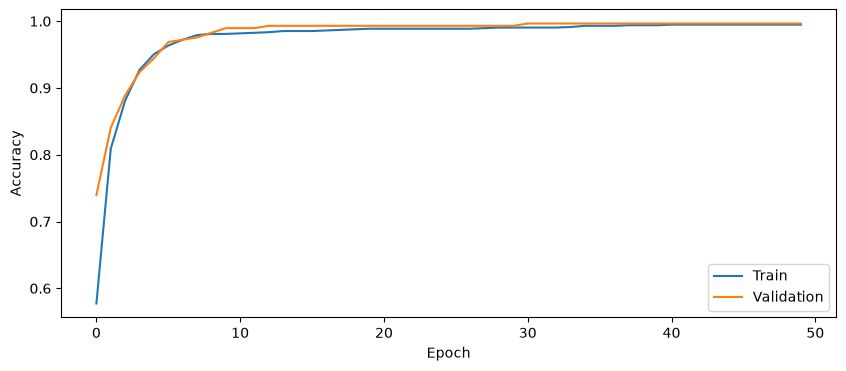

In [38]:
plt.figure(figsize=(10,4))

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.legend(['Train','Validation'])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.show()

## Final Reflection Questions
1. Which classifier achieved the highest accuracy?
2. Which classifier was easiest to interpret?
3. Which features were most important?
4. Why is feature scaling important for kNN and SVM?
5. Why can accuracy be misleading for imbalanced datasets?
6. How did the neural network compare with traditional machine learning models?
7. In a real predictive-maintenance system, what additional sensor measurements might improve performance?